# Loan Rejection Classifier – Improving a Model on a Rare Class

**Dataset:** Loan Prediction dataset (`loan_data.csv`, 614 rows, 13 columns).
**Task:** predict whether a loan application is **rejected** (`Loan_Status = N`).
The rejected class is the minority class (~31%), so it is our **rare / positive class (1)**.

Plan: prepare data → baseline → choose metric → error analysis → improve one change at a time (using cross-validation on the training set only) → feature importance → one final test.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict, StratifiedKFold
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.utils import resample
from sklearn.base import clone

RANDOM_STATE = 42
os.makedirs("figures", exist_ok=True)
plt.rcParams["figure.dpi"] = 100
BLUE, ORANGE, GREY = "#2E6FBA", "#E07B39", "#9AA5B1"

## Step 1 – Prepare the data and look at the class balance

What I do here:
- Drop `Loan_ID` (it is just an ID, it has no meaning for the prediction).
- Change `Dependents = "3+"` to `3` so it becomes a number.
- Fill missing values: **mode** for categorical / discrete columns, **median** for `LoanAmount` (median is safer because loan amounts have outliers).
- Encode the target: `N` (rejected) → **1** (rare class), `Y` (approved) → 0.
- One-hot encode the text columns with `get_dummies(drop_first=True)`.
- 80/20 split with `stratify=y` and `random_state=42`. The test set is **not used again until Step 7**.

> Note: filling with the mode/median of the whole file is a small simplification. The values are simple statistics and barely change if computed on the training set only.

In [2]:
df = pd.read_csv("loan_data.csv")
print("Shape:", df.shape)
df.head()

Shape: (614, 13)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [3]:
print("Missing values per column:")
print(df.isna().sum())

Missing values per column:
Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64


In [4]:
data = df.drop(columns="Loan_ID").copy()
data["Dependents"] = data["Dependents"].replace("3+", "3")

for col in ["Gender", "Married", "Dependents", "Self_Employed", "Credit_History", "Loan_Amount_Term"]:
    data[col] = data[col].fillna(data[col].mode()[0])
data["LoanAmount"] = data["LoanAmount"].fillna(data["LoanAmount"].median())
data["Dependents"] = data["Dependents"].astype(int)

print("Missing values left:", data.isna().sum().sum())

Missing values left: 0


Loan_Status
Y    422
N    192
Name: count, dtype: int64

Loan_Status
Y    0.687
N    0.313
Name: proportion, dtype: float64


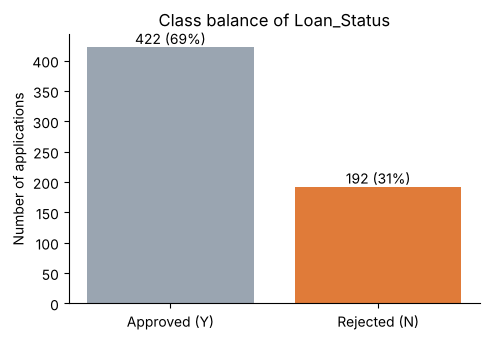

In [5]:
print(data["Loan_Status"].value_counts())
print()
print(data["Loan_Status"].value_counts(normalize=True).round(3))

counts = data["Loan_Status"].value_counts()
fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar(["Approved (Y)", "Rejected (N)"], counts.values, color=[GREY, ORANGE])
ax.bar_label(bars, labels=[f"{v} ({v/len(data):.0%})" for v in counts.values])
ax.set_title("Class balance of Loan_Status")
ax.set_ylabel("Number of applications")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("figures/class_balance.png", dpi=150); plt.show()

In [6]:
y = (data["Loan_Status"] == "N").astype(int)          # 1 = rejected (rare class)
X = pd.get_dummies(data.drop(columns="Loan_Status"), drop_first=True, dtype=int)
print("Features:", list(X.columns))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Rare-class share  train: %.3f  test: %.3f" % (y_train.mean(), y_test.mean()))

Features: ['Dependents', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Gender_Male', 'Married_Yes', 'Education_Not Graduate', 'Self_Employed_Yes', 'Property_Area_Semiurban', 'Property_Area_Urban']


Train: (491, 12)  Test: (123, 12)
Rare-class share  train: 0.314  test: 0.309


The classes are **imbalanced: 422 approved vs 192 rejected (≈ 69% / 31%)**. A model can get about 69% accuracy just by saying "approved" every time, so accuracy alone will be misleading. Thanks to `stratify=y`, train and test both have ≈ 31% rejected loans.

## Step 2 – Baseline models

Two baselines:
1. `DummyClassifier(strategy="most_frequent")` – always predicts "approved".
2. A default `RandomForestClassifier`.

Because the test set is locked until Step 7, I evaluate the baselines with **5-fold stratified cross-validation on the training set** (`cross_val_predict`). Every training row gets a prediction from a model that did not see it.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def rare_scores(y_true, y_pred):
    return {"Accuracy":  accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall":    recall_score(y_true, y_pred),
            "F1":        f1_score(y_true, y_pred)}

def cv_proba(model, X_, y_):
    return cross_val_predict(model, X_, y_, cv=cv, method="predict_proba")[:, 1]

def show_cm(y_true, y_pred, title, fname=None):
    fig, ax = plt.subplots(figsize=(4, 3.5))
    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred),
                           display_labels=["Approved (0)", "Rejected (1)"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(title)
    plt.tight_layout()
    if fname: plt.savefig(fname, dpi=150)
    plt.show()

In [8]:
dummy = DummyClassifier(strategy="most_frequent")
dummy_pred = cross_val_predict(dummy, X_train, y_train, cv=cv)

print("=== DummyClassifier (most_frequent) ===")
print("Accuracy:", round(accuracy_score(y_train, dummy_pred), 3))
print(classification_report(y_train, dummy_pred, target_names=["Approved", "Rejected"], zero_division=0))
print(confusion_matrix(y_train, dummy_pred))

=== DummyClassifier (most_frequent) ===
Accuracy: 0.686
              precision    recall  f1-score   support

    Approved       0.69      1.00      0.81       337
    Rejected       0.00      0.00      0.00       154

    accuracy                           0.69       491
   macro avg       0.34      0.50      0.41       491
weighted avg       0.47      0.69      0.56       491

[[337   0]
 [154   0]]


=== Default RandomForest ===
Accuracy: 0.774
              precision    recall  f1-score   support

    Approved       0.79      0.91      0.85       337
    Rejected       0.71      0.47      0.56       154

    accuracy                           0.77       491
   macro avg       0.75      0.69      0.71       491
weighted avg       0.77      0.77      0.76       491

[[308  29]
 [ 82  72]]


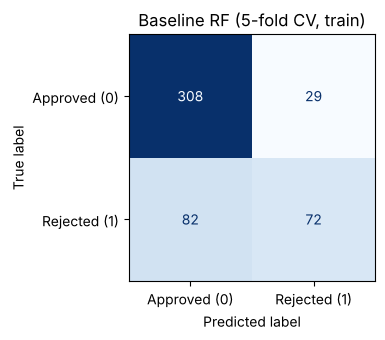

Rejected loans in train: 154  -> caught: 72, MISSED: 82 (53%)


In [9]:
rf_base = RandomForestClassifier(random_state=RANDOM_STATE)
base_proba = cv_proba(rf_base, X_train, y_train)
base_pred = (base_proba >= 0.5).astype(int)

print("=== Default RandomForest ===")
print("Accuracy:", round(accuracy_score(y_train, base_pred), 3))
print(classification_report(y_train, base_pred, target_names=["Approved", "Rejected"]))
cm = confusion_matrix(y_train, base_pred)
print(cm)
show_cm(y_train, base_pred, "Baseline RF (5-fold CV, train)", "figures/cm_baseline.png")

tn, fp, fn, tp = cm.ravel()
print(f"Rejected loans in train: {fn+tp}  -> caught: {tp}, MISSED: {fn} ({fn/(fn+tp):.0%})")

**How many rare-class cases were missed?**
- The **Dummy model** has ~69% accuracy but misses **all 154** rejected loans in the training set (recall = 0).
- The **default Random Forest** reaches ~77% accuracy, but it still misses **82 of 154** rejected loans (≈ 53%). It catches fewer than half of the risky applications.

So the accuracy looks fine, but the model is weak exactly on the class we care about.

## Step 3 – Choose the metric

Positive class = **rejected loan (1)**.
- **False negative (FN):** a loan that should be rejected is predicted "approve" → the bank may give money to someone who cannot pay it back. This can cost the **whole loan amount**.
- **False positive (FP):** a good applicant is flagged as "reject" → the bank loses some interest and the customer is annoyed, but a human officer can review the case.

**FN is the worse mistake**, so my main metric is **Recall of the rejected class**.
Recall alone can be "cheated" (predict everything as rejected → recall = 1), so I add a guard rule: **precision must stay ≥ 0.50** (at least half of the flagged applications are real rejections). I also report F1 so the trade-off is visible.

## Step 4 – Error analysis

I use the cross-validated baseline predictions on the **training set** (not the test set) and split the rows into four groups: TP, TN, FP, FN. Then I compare their feature values.

In [10]:
ea = X_train.copy()
ea["TotalIncome"] = ea["ApplicantIncome"] + ea["CoapplicantIncome"]
ea["LoanToIncome"] = ea["LoanAmount"] * 1000 / ea["TotalIncome"]
ea["true"], ea["pred"], ea["proba"] = y_train.values, base_pred, base_proba

def group(r):
    if r.true == 1 and r.pred == 1: return "TP (caught rejection)"
    if r.true == 1 and r.pred == 0: return "FN (missed rejection)"
    if r.true == 0 and r.pred == 1: return "FP (false alarm)"
    return "TN (correct approval)"
ea["group"] = ea.apply(group, axis=1)
print(ea["group"].value_counts())

cols = ["Credit_History", "ApplicantIncome", "CoapplicantIncome", "TotalIncome",
        "LoanAmount", "LoanToIncome", "Loan_Amount_Term", "Married_Yes", "Property_Area_Semiurban", "proba"]
summary = ea.groupby("group")[cols].mean().round(2).T
summary

group
TN (correct approval)    308
FN (missed rejection)     82
TP (caught rejection)     72
FP (false alarm)          29
Name: count, dtype: int64


group,FN (missed rejection),FP (false alarm),TN (correct approval),TP (caught rejection)
Credit_History,1.00,0.83,1.00,0.10
ApplicantIncome,5350.22,8993.48,5054.27,5913.33
CoapplicantIncome,1949.21,2361.90,1467.91,1321.29
TotalIncome,7299.43,11355.38,6522.18,7234.62
LoanAmount,151.00,226.38,134.64,142.90
LoanToIncome,25.77,25.33,22.98,24.35
Loan_Amount_Term,337.02,316.55,343.21,349.17
Married_Yes,0.54,0.48,0.70,0.58
Property_Area_Semiurban,0.27,0.31,0.42,0.28
proba,0.23,0.61,0.18,0.84


In [11]:
fn_rows = ea[ea.group.str.startswith("FN")]
tp_rows = ea[ea.group.str.startswith("TP")]
print("Credit_History among missed rejections (FN):")
print(fn_rows["Credit_History"].value_counts())
print("\nCredit_History among caught rejections (TP):")
print(tp_rows["Credit_History"].value_counts())
print("\nLoanToIncome – FN vs TN")
print(ea[ea.group.str[:2].isin(["FN", "TN"])].groupby("group")["LoanToIncome"].describe().round(1))

Credit_History among missed rejections (FN):
Credit_History
1.0    82
Name: count, dtype: int64

Credit_History among caught rejections (TP):
Credit_History
0.0    65
1.0     7
Name: count, dtype: int64

LoanToIncome – FN vs TN
                       count  mean   std  min   25%   50%   75%   max
group                                                                
FN (missed rejection)   82.0  25.8  12.4  2.5  19.0  23.7  29.6  69.2
TN (correct approval)  308.0  23.0   7.2  2.7  19.0  23.9  27.8  44.4


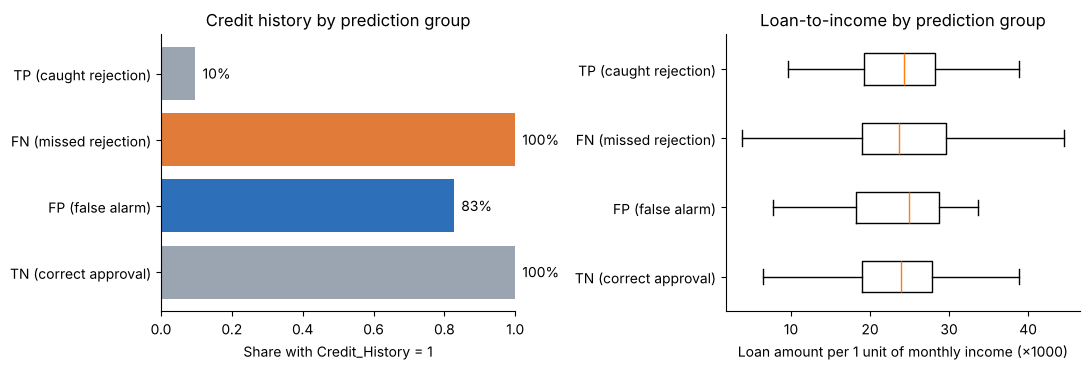

In [12]:
order = ["TN (correct approval)", "FP (false alarm)", "FN (missed rejection)", "TP (caught rejection)"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

ch = ea.groupby("group")["Credit_History"].mean().reindex(order)
axes[0].barh(order, ch.values, color=[GREY, BLUE, ORANGE, GREY])
axes[0].set_xlim(0, 1); axes[0].set_xlabel("Share with Credit_History = 1")
axes[0].set_title("Credit history by prediction group")
for i, v in enumerate(ch.values): axes[0].text(v + 0.02, i, f"{v:.0%}", va="center")

data_box = [ea.loc[ea.group == g, "LoanToIncome"].clip(upper=100) for g in order]
axes[1].boxplot(data_box, vert=False, showfliers=False)
axes[1].set_yticks(range(1, 5), order)
axes[1].set_xlabel("Loan amount per 1 unit of monthly income (×1000)")
axes[1].set_title("Loan-to-income by prediction group")
for ax in axes: ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("figures/error_analysis.png", dpi=150); plt.show()

**Patterns I found**

1. **The model is basically a `Credit_History` rule.** **All 82** missed rejections (FN) have `Credit_History = 1` (good history), while **65 of the 72** caught rejections (TP) have `Credit_History = 0`. *Guess:* the forest learned "bad credit history → reject" very well, but it has almost no signal for rejected applicants who **do** have a good credit history – for them it looks like a normal approval.
2. **False alarms (FP) are big, high-income applications.** The FP group has a much higher applicant income (≈ 9,000 vs ≈ 5,000 for correct approvals) and a much bigger loan amount (≈ 226 vs ≈ 135). *Guess:* these rows are rare/extreme values, the trees have few similar examples, so they get unstable "risky" predictions. Income and loan amount only make sense **together**.
3. **Missed rejections have a slightly worse loan-to-income ratio, but only in the tail.** The median is the same as for correct approvals (≈ 24), but the FN group has a longer tail (75th percentile 29.6 vs 27.8, max 69 vs 44), fewer married applicants (54% vs 70%) and fewer semi-urban properties (27% vs 42%). *Guess:* the model sees income and loan amount as separate columns and cannot easily learn "loan too big for the income". → **Idea for Step 5: add ratio features** (total income, EMI, loan-to-income).
4. The FN rows get an average probability of only **0.23** (TN: 0.18). *Guess:* a lower threshold can catch some of them, but it will also create many more false alarms because the two groups overlap.

## Step 5 – Improve the model (one change at a time)

All numbers here come from **5-fold cross-validation on the training set**. The test set is still untouched.

First I try each change **on its own against the baseline**, so I know which single change helps:
- **A)** `class_weight="balanced"`
- **B)** different thresholds (0.5, 0.4, 0.3, 0.2, 0.1)
- **C)** resampling: upsample the rejected class (training folds only, inside CV)
- **D)** new features (from the error analysis)
- **E)** removing weak features

Then I build the final model **step by step**, adding one winning change at a time.

In [13]:
results = []
def log(name, y_pred, store=True):
    r = {"Version": name, **rare_scores(y_train, y_pred)}
    if store: results.append(r)
    return r

log("Baseline RF (thr 0.5)", base_pred)

# A) class_weight="balanced"
proba_A = cv_proba(RandomForestClassifier(random_state=RANDOM_STATE, class_weight="balanced"), X_train, y_train)
log("A) class_weight='balanced'", (proba_A >= 0.5).astype(int))
pd.DataFrame(results).round(3)

,Version,Accuracy,Precision,Recall,F1
0,Baseline RF (thr 0.5),0.774,0.713,0.468,0.565
1,A) class_weight='balanced',0.733,0.588,0.500,0.540


In [14]:
# B) Threshold on the baseline model (same probabilities, only the cut-off changes)
thr_rows = []
for t in [0.5, 0.4, 0.3, 0.2, 0.1]:
    thr_rows.append({"Threshold": t, **rare_scores(y_train, (base_proba >= t).astype(int))})
thr_table = pd.DataFrame(thr_rows).round(3)
thr_table

,Threshold,Accuracy,Precision,Recall,F1
0,0.5,0.774,0.713,0.468,0.565
1,0.4,0.741,0.600,0.526,0.561
2,0.3,0.692,0.508,0.643,0.567
3,0.2,0.617,0.437,0.766,0.557
4,0.1,0.503,0.379,0.916,0.536


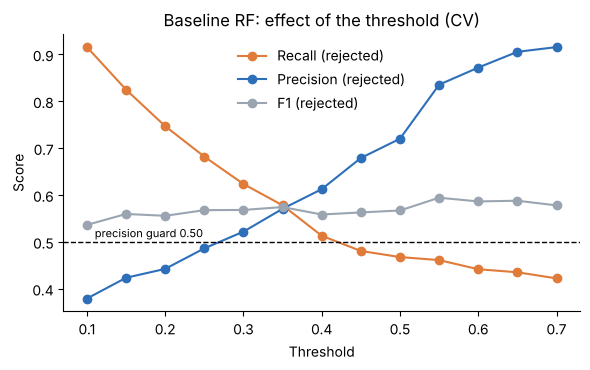

In [15]:
fig, ax = plt.subplots(figsize=(6, 3.8))
ts = np.arange(0.1, 0.71, 0.05)
P = [precision_score(y_train, (base_proba >= t).astype(int), zero_division=0) for t in ts]
R = [recall_score(y_train, (base_proba >= t).astype(int)) for t in ts]
F = [f1_score(y_train, (base_proba >= t).astype(int)) for t in ts]
ax.plot(ts, R, marker="o", color=ORANGE, label="Recall (rejected)")
ax.plot(ts, P, marker="o", color=BLUE, label="Precision (rejected)")
ax.plot(ts, F, marker="o", color=GREY, label="F1 (rejected)")
ax.axhline(0.5, ls="--", lw=1, color="black"); ax.text(0.11, 0.51, "precision guard 0.50", fontsize=8)
ax.set_xlabel("Threshold"); ax.set_ylabel("Score"); ax.set_title("Baseline RF: effect of the threshold (CV)")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("figures/threshold_curve.png", dpi=150); plt.show()

log("B) threshold 0.3 (baseline model)", (base_proba >= 0.3).astype(int));

In [16]:
# C) Upsampling the rare class – done INSIDE each CV fold, on the training part only
def cv_proba_upsampled(model, X_, y_):
    proba = np.zeros(len(y_))
    for tr_idx, va_idx in cv.split(X_, y_):
        X_tr, y_tr = X_.iloc[tr_idx], y_.iloc[tr_idx]
        majority, minority = X_tr[y_tr == 0], X_tr[y_tr == 1]
        minority_up = resample(minority, replace=True, n_samples=len(majority), random_state=RANDOM_STATE)
        X_bal = pd.concat([majority, minority_up])
        y_bal = np.r_[np.zeros(len(majority)), np.ones(len(minority_up))]
        m = clone(model).fit(X_bal, y_bal)
        proba[va_idx] = m.predict_proba(X_.iloc[va_idx])[:, 1]   # validation fold is NOT resampled
    return proba

proba_C = cv_proba_upsampled(RandomForestClassifier(random_state=RANDOM_STATE), X_train, y_train)
log("C) upsampling (train folds only)", (proba_C >= 0.5).astype(int));

In [17]:
# D) New features – idea from the error analysis (loan size relative to income)
def add_features(X_):
    X_ = X_.copy()
    X_["TotalIncome"] = X_["ApplicantIncome"] + X_["CoapplicantIncome"]
    X_["EMI"] = X_["LoanAmount"] / X_["Loan_Amount_Term"]             # rough monthly payment
    X_["LoanToIncome"] = X_["LoanAmount"] * 1000 / X_["TotalIncome"]
    X_["EMIToIncome"] = X_["EMI"] * 1000 / X_["TotalIncome"]
    return X_

X_train_fe = add_features(X_train)
proba_D = cv_proba(RandomForestClassifier(random_state=RANDOM_STATE), X_train_fe, y_train)
log("D) + new ratio features", (proba_D >= 0.5).astype(int));

In [18]:
# E) Remove the 5 weakest features of the baseline model
imp_base = pd.Series(RandomForestClassifier(random_state=RANDOM_STATE).fit(X_train, y_train).feature_importances_,
                     index=X_train.columns).sort_values()
weak = list(imp_base.index[:5])
print("Weakest 5 features:", weak)
proba_E = cv_proba(RandomForestClassifier(random_state=RANDOM_STATE), X_train.drop(columns=weak), y_train)
log("E) drop 5 weakest features", (proba_E >= 0.5).astype(int))

single_changes = pd.DataFrame(results).round(3)
single_changes

Weakest 5 features: ['Self_Employed_Yes', 'Gender_Male', 'Property_Area_Urban', 'Education_Not Graduate', 'Married_Yes']


,Version,Accuracy,Precision,Recall,F1
0,Baseline RF (thr 0.5),0.774,0.713,0.468,0.565
1,A) class_weight='balanced',0.733,0.588,0.500,0.540
2,B) threshold 0.3 (baseline model),0.692,0.508,0.643,0.567
3,C) upsampling (train folds only),0.772,0.702,0.474,0.566
4,D) + new ratio features,0.792,0.741,0.519,0.611
5,E) drop 5 weakest features,0.766,0.679,0.481,0.563


**What the single changes tell me (rare class, CV on train):**
- **A) class_weight="balanced"** raises recall a little but lowers precision and F1. On its own the effect is small, because a Random Forest with fully grown trees still fits the training data almost perfectly.
- **B) Threshold** is the strongest lever for recall: going from 0.5 to 0.3 raises recall a lot, but precision drops. At 0.2 and 0.1 precision falls well below my 0.50 guard (too many false alarms).
- **C) Upsampling** changes almost nothing – the duplicated rows are memorised by the deep trees.
- **D) New ratio features** is the best single change: recall **and** precision both go up, so F1 improves clearly. This confirms the error-analysis idea.
- **E) Dropping weak features** makes things slightly worse, so I keep them.

Now I build the final model **cumulatively**, one change per row:
1. Baseline → 2. + new features (D) → 3. + `class_weight="balanced"` (A) → 4. + tuned threshold (B).

In [19]:
steps = []
def step_log(name, y_pred):
    steps.append({"Version": name, **rare_scores(y_train, y_pred)})

step_log("V1 Baseline RF", base_pred)
step_log("V2 + new features", (proba_D >= 0.5).astype(int))

rf_final = RandomForestClassifier(random_state=RANDOM_STATE, class_weight="balanced")
proba_V3 = cv_proba(rf_final, X_train_fe, y_train)
step_log("V3 + class_weight='balanced'", (proba_V3 >= 0.5).astype(int))

thr_rows_v3 = [{"Threshold": t, **rare_scores(y_train, (proba_V3 >= t).astype(int))}
               for t in [0.5, 0.45, 0.4, 0.35, 0.3, 0.2, 0.1]]
thr_v3 = pd.DataFrame(thr_rows_v3).round(3)
thr_v3

,Threshold,Accuracy,Precision,Recall,F1
0,0.50,0.768,0.652,0.558,0.601
1,0.45,0.747,0.596,0.604,0.600
2,0.40,0.723,0.547,0.682,0.607
3,0.35,0.672,0.485,0.721,0.580
4,0.30,0.631,0.448,0.760,0.564
5,0.20,0.536,0.394,0.890,0.546
6,0.10,0.405,0.342,0.974,0.507


In [20]:
# Pick the threshold with the HIGHEST RECALL while precision stays >= 0.50 (rule from Step 3)
ok = thr_v3[thr_v3["Precision"] >= 0.50]
best_thr = float(ok.sort_values(["Recall", "Threshold"], ascending=[False, False]).iloc[0]["Threshold"])
print("Chosen threshold:", best_thr)

step_log(f"V4 + threshold {best_thr}", (proba_V3 >= best_thr).astype(int))
step_table = pd.DataFrame(steps).round(3)
step_table

Chosen threshold: 0.4


,Version,Accuracy,Precision,Recall,F1
0,V1 Baseline RF,0.774,0.713,0.468,0.565
1,V2 + new features,0.792,0.741,0.519,0.611
2,V3 + class_weight='balanced',0.768,0.652,0.558,0.601
3,V4 + threshold 0.4,0.723,0.547,0.682,0.607


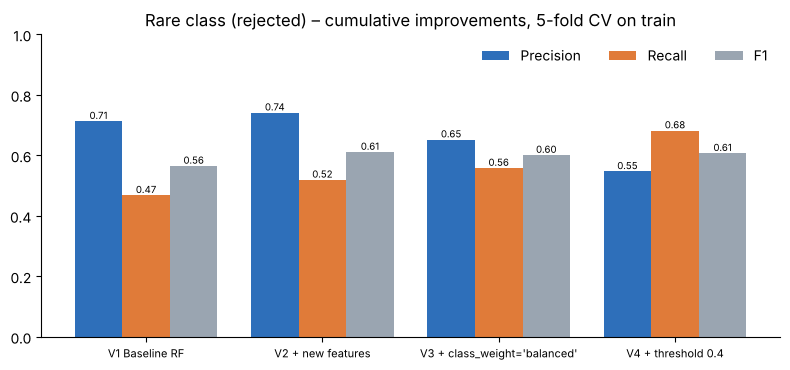

In [21]:
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(step_table)); w = 0.27
for i, (m, c) in enumerate([("Precision", BLUE), ("Recall", ORANGE), ("F1", GREY)]):
    b = ax.bar(x + (i - 1) * w, step_table[m], w, label=m, color=c)
    ax.bar_label(b, fmt="%.2f", fontsize=7)
ax.set_xticks(x, step_table["Version"], fontsize=8)
ax.set_ylim(0, 1); ax.set_title("Rare class (rejected) – cumulative improvements, 5-fold CV on train")
ax.legend(frameon=False, ncol=3); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("figures/improvements.png", dpi=150); plt.show()

**Result of Step 5 (CV on train):** recall of the rejected class went from about **0.47 → 0.68** while precision stayed above 0.50 and F1 also improved slightly. Each row changes only one thing, so I can see that new features gave the cleanest gain and the threshold gave the biggest recall gain.

## Step 6 – Feature importance

I fit the final model (`class_weight="balanced"` + new features) on the **full training set** and look at the Random Forest importances.

Credit_History             0.209
LoanToIncome               0.104
TotalIncome                0.102
EMIToIncome                0.102
ApplicantIncome            0.093
EMI                        0.091
LoanAmount                 0.084
CoapplicantIncome          0.069
Property_Area_Semiurban    0.028
Dependents                 0.026
Loan_Amount_Term           0.020
Married_Yes                0.019
Gender_Male                0.015
Education_Not Graduate     0.015
Property_Area_Urban        0.012
Self_Employed_Yes          0.011
dtype: float64


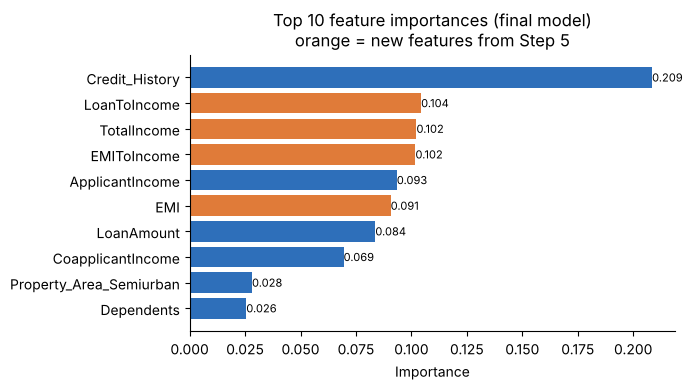

In [22]:
rf_final.fit(X_train_fe, y_train)
importances = pd.Series(rf_final.feature_importances_, index=X_train_fe.columns).sort_values(ascending=False)
print(importances.round(3))

top10 = importances.head(10)[::-1]
fig, ax = plt.subplots(figsize=(7, 4))
colors = [ORANGE if f in ["TotalIncome", "EMI", "LoanToIncome", "EMIToIncome"] else BLUE for f in top10.index]
bars = ax.barh(top10.index, top10.values, color=colors)
ax.bar_label(bars, fmt="%.3f", fontsize=8)
ax.set_title("Top 10 feature importances (final model)\norange = new features from Step 5")
ax.set_xlabel("Importance"); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("figures/feature_importance.png", dpi=150); plt.show()

**Top 3 features in simple words**
1. **Credit_History** – whether the applicant's past credit record meets the bank's rules. People with a bad record are rejected far more often. This is by far the strongest signal.
2. **LoanToIncome** (new feature) – how big the loan is compared with the household income. A loan that is too big for the income is risky. (`EMIToIncome`, the monthly payment vs income, is almost as important.)
3. **TotalIncome** (new feature) – applicant + co-applicant income together. More household income means the loan is easier to repay.

Three of the top four features are the new features from Step 5, which confirms the error-analysis idea.

**Possible leakage?** `Credit_History` is much higher than everything else. I checked whether it could be leakage: it is information that the bank **has at application time** (it comes from the credit bureau, before the decision), so it is not a copy of the target. It is a legitimate but very dominant feature. The risk is more that the model depends too much on one column (as seen in the error analysis). No feature is a direct copy of `Loan_Status`, and `Loan_ID` was already dropped.

In [23]:
# Remove the least important features and check with CV (still train only)
drop_rows = []
for k in [0, 3, 5, 8]:
    least = list(importances.index[::-1][:k])
    p = cv_proba(RandomForestClassifier(random_state=RANDOM_STATE, class_weight="balanced"),
                 X_train_fe.drop(columns=least), y_train)
    drop_rows.append({"Removed": k, "Features left": X_train_fe.shape[1] - k,
                      **rare_scores(y_train, (p >= best_thr).astype(int))})
    if k: print(f"k={k}: removed {least}")
drop_table = pd.DataFrame(drop_rows).round(3)
drop_table

k=3: removed ['Self_Employed_Yes', 'Property_Area_Urban', 'Education_Not Graduate']


k=5: removed ['Self_Employed_Yes', 'Property_Area_Urban', 'Education_Not Graduate', 'Gender_Male', 'Married_Yes']


k=8: removed ['Self_Employed_Yes', 'Property_Area_Urban', 'Education_Not Graduate', 'Gender_Male', 'Married_Yes', 'Loan_Amount_Term', 'Dependents', 'Property_Area_Semiurban']


,Removed,Features left,Accuracy,Precision,Recall,F1
0,0,16,0.723,0.547,0.682,0.607
1,3,13,0.690,0.505,0.662,0.573
2,5,11,0.701,0.519,0.630,0.569
3,8,8,0.711,0.532,0.649,0.585


**What happens when I remove the least important features?** Every version with fewer features is a bit **worse**: removing the 3 weakest (self-employed, urban area, education) already drops recall from 0.68 to 0.66 and F1 from 0.61 to 0.57. Each weak feature carries only a little information, but together they still help a bit, and a Random Forest is not hurt by a few weak columns. So I **keep all 16 features** in the final model.

## Step 7 – Final test (the test set is used ONCE)

All choices are fixed now (features, `class_weight`, threshold). I train every version on the full training set and evaluate on the test set **one time**.

In [24]:
X_test_fe = add_features(X_test)

final_rows = []
def test_eval(name, model, Xtr_, Xte_, thr=0.5):
    model.fit(Xtr_, y_train)
    pred = (model.predict_proba(Xte_)[:, 1] >= thr).astype(int)
    final_rows.append({"Version": name, **rare_scores(y_test, pred)})
    return pred

test_eval("Dummy (most_frequent)", DummyClassifier(strategy="most_frequent"), X_train, X_test)
pred_base = test_eval("V1 Baseline RF", RandomForestClassifier(random_state=RANDOM_STATE), X_train, X_test)
test_eval("V2 + new features", RandomForestClassifier(random_state=RANDOM_STATE), X_train_fe, X_test_fe)
test_eval("V3 + class_weight='balanced'", RandomForestClassifier(random_state=RANDOM_STATE, class_weight="balanced"), X_train_fe, X_test_fe)
pred_final = test_eval(f"V4 Final (threshold {best_thr})",
                       RandomForestClassifier(random_state=RANDOM_STATE, class_weight="balanced"), X_train_fe, X_test_fe, best_thr)

final_table = pd.DataFrame(final_rows).round(3)
final_table.to_csv("figures/final_table.csv", index=False)
final_table

,Version,Accuracy,Precision,Recall,F1
0,Dummy (most_frequent),0.691,0.000,0.000,0.000
1,V1 Baseline RF,0.780,0.690,0.526,0.597
2,V2 + new features,0.772,0.656,0.553,0.600
3,V3 + class_weight='balanced',0.748,0.600,0.553,0.575
4,V4 Final (threshold 0.4),0.691,0.500,0.658,0.568


=== Final model on TEST ===
              precision    recall  f1-score   support

    Approved       0.82      0.71      0.76        85
    Rejected       0.50      0.66      0.57        38

    accuracy                           0.69       123
   macro avg       0.66      0.68      0.66       123
weighted avg       0.72      0.69      0.70       123



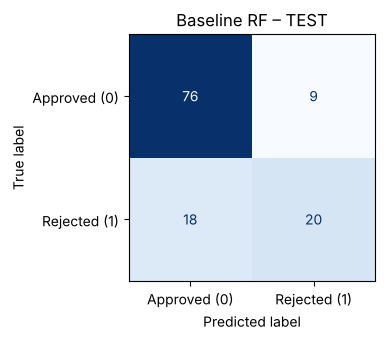

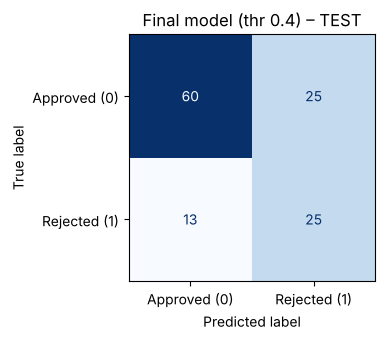

Baseline: caught 20/38 rejections, missed 18, false alarms 9
Final   : caught 25/38 rejections, missed 13, false alarms 25


In [25]:
print("=== Final model on TEST ===")
print(classification_report(y_test, pred_final, target_names=["Approved", "Rejected"]))
show_cm(y_test, pred_base, "Baseline RF – TEST", "figures/cm_test_baseline.png")
show_cm(y_test, pred_final, f"Final model (thr {best_thr}) – TEST", "figures/cm_test_final.png")

for name, p in [("Baseline", pred_base), ("Final", pred_final)]:
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()
    print(f"{name:8s}: caught {tp}/{tp+fn} rejections, missed {fn}, false alarms {fp}")

**Decision**

On the test set the final model (V4) catches **25 of 38** rejected loans instead of 20 (recall **0.53 → 0.66**), so **5 fewer risky loans are missed**. The price is **16 more false alarms** (9 → 25): precision drops from 0.69 to 0.50, accuracy from 0.78 to 0.69, and F1 is slightly lower (0.60 → 0.57).

**Which version would I use?** I would use **V4** in real life, because my main metric is recall: for a bank a missed bad loan can cost the whole loan amount, while a false alarm costs much less. It still meets my rule (precision ≥ 0.50 – one real rejection for every false alarm).
**Trade-off:** more good applicants get flagged. I would not reject them automatically – flagged applications should go to a **loan officer for manual review**, so a false alarm only costs review time. If the bank has **no** capacity for manual review, V2 (new features, threshold 0.5) is the more balanced choice: similar F1 to the baseline but higher recall.

**Note:** the test set is small (123 rows, only 38 rejections), so one application changes recall by ≈ 2.6 percentage points. The test results are close to the CV results, which means the choices made on the training data were not overfitted.